## Imports

In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

#Agregar root al path de búsqueda de módulos
sys.path.append("..") 


In [2]:
## Ajustar algunas propiedades de este notebook
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

## Cargar datos

In [3]:
root = ".."
folder_raw_datasets = "datasets/raw"
data_version = "20261028"
file_calendar = "calendar.csv"
file_stores = "stores.csv"
file_transactions = "transactions.csv"

route_calendar = os.path.join(root,folder_raw_datasets,data_version,file_calendar)
route_stores = os.path.join(root,folder_raw_datasets,data_version,file_stores)
route_transactions = os.path.join(root,folder_raw_datasets,data_version,file_transactions)

calendar = pd.read_csv(route_calendar)
stores = pd.read_csv(route_stores)
transactions = pd.read_csv(route_transactions)

## Exploración inicial y conversiones de tipo de los datos

Se realizará estadística descriptiva (muy básica) a los datos entregados; posteriormente se revisará cada una de las columnas de cada unos de los datasets con la finalidad de entender el contenido de los datasets, si hay valores ausentes o nulos, cómo podrían reemplazarse; así como sentar las bases necesarias para poder elaborar una pregunta específica que aporte valor al negocio.

Posteriormente, en la sección de "Preparación de datos" este análisis exploratorio será utilizado para preparar un dataset de datos procesados que aporten la información necesaria para resolver una duda específica del negocio.

Nota: a modo de demostración se realizó un análisis detallado de cada columna del dataset **Calendar**; 
sin embargo en los demás datasets se realizará un análisis más general basado en los métodos _describe_ e _info_

### Calendar

In [4]:
calendar.head(3)

,date,day_of_week,day_name,week_of_year,month,year,quarter,season,is_holiday,holiday_name,is_payday,is_weekend,is_navidad_season,is_buen_fin,is_semana_santa
0,2023-01-01,6,Sunday,52,1,2023,1,Invierno,True,Año Nuevo,False,True,True,False,False
1,2023-01-02,0,Monday,1,1,2023,1,Invierno,False,NaN,False,False,True,False,False
2,2023-01-03,1,Tuesday,1,1,2023,1,Invierno,False,NaN,False,False,True,False,False


In [5]:
calendar.info()

<class 'pandas.DataFrame'>
RangeIndex: 425 entries, 0 to 424
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   date               425 non-null    str  
 1   day_of_week        425 non-null    int64
 2   day_name           425 non-null    str  
 3   week_of_year       425 non-null    int64
 4   month              425 non-null    int64
 5   year               425 non-null    int64
 6   quarter            425 non-null    int64
 7   season             425 non-null    str  
 8   is_holiday         425 non-null    bool 
 9   holiday_name       18 non-null     str  
 10  is_payday          425 non-null    bool 
 11  is_weekend         425 non-null    bool 
 12  is_navidad_season  425 non-null    bool 
 13  is_buen_fin        425 non-null    bool 
 14  is_semana_santa    425 non-null    bool 
dtypes: bool(6), int64(5), str(4)
memory usage: 32.5 KB


In [6]:
calendar.describe()

,day_of_week,week_of_year,month,year,quarter
count,425.000000,425.000000,425.000000,425.000000,425.000000
mean,2.992941,23.496471,5.814118,2023.141176,2.296471
std,2.004111,15.917701,3.655029,0.348614,1.162143
min,0.000000,1.000000,1.000000,2023.000000,1.000000
25%,1.000000,8.000000,2.000000,2023.000000,1.000000
50%,3.000000,22.000000,6.000000,2023.000000,2.000000
75%,5.000000,37.000000,9.000000,2023.000000,3.000000
max,6.000000,52.000000,12.000000,2024.000000,4.000000


In [7]:
# date
calendar["date"] = pd.to_datetime(calendar["date"],format="%Y-%m-%d") 
# no le pongo errors="coerce" porque quiero darme cuenta si algo está mal con el formato de las fechas.

#Explorar nulos o ausentes
print(f"cantidad de datos nulos/ausentes: {calendar['date'].isnull().sum()}")

# Explorar rango de datos y ver si coincide con lo indicado en data_dictionary.md
print(f"Rango de fechas: {calendar['date'].min()} - {calendar['date'].max()}")

cantidad de datos nulos/ausentes: 0
Rango de fechas: 2023-01-01 00:00:00 - 2024-02-29 00:00:00


In [8]:
# day_of_week	
# El tipo de datos es int64; podríamos ahorrar memoria usando un tipo int8, ya que los valores de día de la semana van de 1 a 7.
calendar["day_of_week"] = calendar["day_of_week"].astype("int8")
print(f"cantidad de días contados")
print(f"{calendar['day_of_week'].value_counts()}")
print("")
print(f"cantidad de datos nulos/ausentes: {calendar['day_of_week'].isnull().sum()}")
print(f"Rango de días de la semana: {calendar['day_of_week'].min()} - {calendar['day_of_week'].max()}")

cantidad de días contados
day_of_week
6    61
0    61
1    61
2    61
3    61
4    60
5    60
Name: count, dtype: int64

cantidad de datos nulos/ausentes: 0
Rango de días de la semana: 0 - 6


In [9]:
# day_name
calendar["day_name"].value_counts()
print(f"cantidad de datos nulos/ausentes: {calendar['day_name'].isnull().sum()}")
print(f"Dias de la semana = {calendar['day_name'].unique()}")

cantidad de datos nulos/ausentes: 0
Dias de la semana = <StringArray>
['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
Length: 7, dtype: str


In [10]:
# week_of_year
# El tipo de datos es int64; podríamos ahorrar memoria usando un tipo int8, ya que los valores de semana del año van de 1 a 52.
calendar["week_of_year"] = calendar["week_of_year"].astype("int8")
print(f"cantidad de datos nulos/ausentes: {calendar['week_of_year'].isnull().sum()}")
print(f"Rango de semanas del año: {calendar['week_of_year'].min()} - {calendar['week_of_year'].max()}")


cantidad de datos nulos/ausentes: 0
Rango de semanas del año: 1 - 52


In [11]:
# month	
# El tipo de datos es int64; podríamos ahorrar memoria usando un tipo int8, ya que los valores de mes van de 1 a 12.
calendar["month"] = calendar["month"].astype("int8")
print(f"cantidad de datos nulos/ausentes: {calendar['month'].isnull().sum()}")
print(f"Rango de meses: {calendar['month'].min()} - {calendar['month'].max()}")


cantidad de datos nulos/ausentes: 0
Rango de meses: 1 - 12


In [12]:
# year	
# El tipo de datos es int64; podríamos ahorrar memoria usando un tipo int16, ya que los valores de año no son tan grandes.
calendar["year"] = calendar["year"].astype("int16")
print(f"cantidad de datos nulos/ausentes: {calendar['year'].isnull().sum()}")
print(f"Rango de años: {calendar['year'].min()} - {calendar['year'].max()}")


cantidad de datos nulos/ausentes: 0
Rango de años: 2023 - 2024


In [13]:
# quarter	
# El tipo de datos es int64; podríamos ahorrar memoria usando un tipo int8, ya que los valores de trimestre van de 1 a 4.
calendar["quarter"] = calendar["quarter"].astype("int8")
print(f"cantidad de datos nulos/ausentes: {calendar['quarter'].isnull().sum()}")
print(f"Rango de trimestres: {calendar['quarter'].min()} - {calendar['quarter'].max()}")


cantidad de datos nulos/ausentes: 0
Rango de trimestres: 1 - 4


In [14]:
# season
print(f"cantidad de datos nulos/ausentes: {calendar['season'].isnull().sum()}")
print(f"Valores únicos de temporadas: {calendar['season'].unique()}")

cantidad de datos nulos/ausentes: 0
Valores únicos de temporadas: <StringArray>
['Invierno', 'Primavera', 'Verano', 'Otoño']
Length: 4, dtype: str


In [15]:
# is_holiday
print(f"cantidad de datos nulos/ausentes: {calendar['is_holiday'].isnull().sum()}")
print(f"Valores únicos de is_holiday: {calendar['is_holiday'].unique()}")


cantidad de datos nulos/ausentes: 0
Valores únicos de is_holiday: [ True False]


In [16]:
# holiday_name
print(f"cantidad de datos nulos/ausentes: {calendar['holiday_name'].isnull().sum()}")
print(f"Valores únicos de holiday_name: {calendar['holiday_name'].unique()}")

cantidad de datos nulos/ausentes: 407
Valores únicos de holiday_name: <StringArray>
[                     'Año Nuevo',                              nan,
         'Día de la Constitución',        'Natalicio Benito Juárez',
                   'Jueves Santo',                  'Viernes Santo',
                'Día del Trabajo',        'Día de la Independencia',
                 'Día de Muertos',                       'Buen Fin',
 'Revolución Mexicana / Buen Fin',            'Virgen de Guadalupe',
                     'Nochebuena',                        'Navidad',
                     'Fin de Año']
Length: 15, dtype: str


In [17]:
# ver cuales son las filas de datos nulos
df_nulos_temporal = calendar[calendar['holiday_name'].isnull()]
df_nulos_temporal.head(10)
# se aprecia que los valores nulos corresponden a los días que no son feriados y por eso son tantos (407)

,date,day_of_week,day_name,week_of_year,month,year,quarter,season,is_holiday,holiday_name,is_payday,is_weekend,is_navidad_season,is_buen_fin,is_semana_santa
1,2023-01-02,0,Monday,1,1,2023,1,Invierno,False,NaN,False,False,True,False,False
2,2023-01-03,1,Tuesday,1,1,2023,1,Invierno,False,NaN,False,False,True,False,False
3,2023-01-04,2,Wednesday,1,1,2023,1,Invierno,False,NaN,False,False,True,False,False
4,2023-01-05,3,Thursday,1,1,2023,1,Invierno,False,NaN,False,False,True,False,False
5,2023-01-06,4,Friday,1,1,2023,1,Invierno,False,NaN,False,False,True,False,False
6,2023-01-07,5,Saturday,1,1,2023,1,Invierno,False,NaN,False,True,False,False,False
7,2023-01-08,6,Sunday,1,1,2023,1,Invierno,False,NaN,False,True,False,False,False
8,2023-01-09,0,Monday,2,1,2023,1,Invierno,False,NaN,False,False,False,False,False
9,2023-01-10,1,Tuesday,2,1,2023,1,Invierno,False,NaN,False,False,False,False,False
10,2023-01-11,2,Wednesday,2,1,2023,1,Invierno,False,NaN,False,False,False,False,False


In [18]:
# Estos se pueden agrupar para una exploración en conjunto; 
# Se listan las columnas que representan eventos especiales o días importantes
# is_payday	
# is_weekend	
# is_navidad_season	
# is_buen_fin	
# is_semana_santa

calendar_payday = calendar[calendar['is_payday']==True]
calendar_payday.head(5)

,date,day_of_week,day_name,week_of_year,month,year,quarter,season,is_holiday,holiday_name,is_payday,is_weekend,is_navidad_season,is_buen_fin,is_semana_santa
14,2023-01-15,6,Sunday,2,1,2023,1,Invierno,False,NaN,True,True,False,False,False
30,2023-01-31,1,Tuesday,5,1,2023,1,Invierno,False,NaN,True,False,False,False,False
45,2023-02-15,2,Wednesday,7,2,2023,1,Invierno,False,NaN,True,False,False,False,False
58,2023-02-28,1,Tuesday,9,2,2023,1,Invierno,False,NaN,True,False,False,False,False
73,2023-03-15,2,Wednesday,11,3,2023,1,Primavera,False,NaN,True,False,False,False,False


In [19]:
calendar_weekend = calendar[calendar['is_weekend']==True]
calendar_weekend.head(5)

,date,day_of_week,day_name,week_of_year,month,year,quarter,season,is_holiday,holiday_name,is_payday,is_weekend,is_navidad_season,is_buen_fin,is_semana_santa
0,2023-01-01,6,Sunday,52,1,2023,1,Invierno,True,Año Nuevo,False,True,True,False,False
6,2023-01-07,5,Saturday,1,1,2023,1,Invierno,False,NaN,False,True,False,False,False
7,2023-01-08,6,Sunday,1,1,2023,1,Invierno,False,NaN,False,True,False,False,False
13,2023-01-14,5,Saturday,2,1,2023,1,Invierno,False,NaN,False,True,False,False,False
14,2023-01-15,6,Sunday,2,1,2023,1,Invierno,False,NaN,True,True,False,False,False


In [20]:
calendar_navidad_season = calendar[calendar['is_navidad_season']==True]
calendar_navidad_season.head(5)


,date,day_of_week,day_name,week_of_year,month,year,quarter,season,is_holiday,holiday_name,is_payday,is_weekend,is_navidad_season,is_buen_fin,is_semana_santa
0,2023-01-01,6,Sunday,52,1,2023,1,Invierno,True,Año Nuevo,False,True,True,False,False
1,2023-01-02,0,Monday,1,1,2023,1,Invierno,False,NaN,False,False,True,False,False
2,2023-01-03,1,Tuesday,1,1,2023,1,Invierno,False,NaN,False,False,True,False,False
3,2023-01-04,2,Wednesday,1,1,2023,1,Invierno,False,NaN,False,False,True,False,False
4,2023-01-05,3,Thursday,1,1,2023,1,Invierno,False,NaN,False,False,True,False,False


In [21]:
calendar_buen_fin = calendar[calendar['is_buen_fin']==True]
calendar_buen_fin.head(5)

,date,day_of_week,day_name,week_of_year,month,year,quarter,season,is_holiday,holiday_name,is_payday,is_weekend,is_navidad_season,is_buen_fin,is_semana_santa
320,2023-11-17,4,Friday,46,11,2023,4,Otoño,True,Buen Fin,False,False,False,True,False
321,2023-11-18,5,Saturday,46,11,2023,4,Otoño,True,Buen Fin,False,True,False,True,False
322,2023-11-19,6,Sunday,46,11,2023,4,Otoño,True,Buen Fin,False,True,False,True,False
323,2023-11-20,0,Monday,47,11,2023,4,Otoño,True,Revolución Mexicana / Buen Fin,False,False,False,True,False


In [22]:
calendar_semana_santa = calendar[calendar['is_semana_santa']==True]
calendar_semana_santa.head(5)

,date,day_of_week,day_name,week_of_year,month,year,quarter,season,is_holiday,holiday_name,is_payday,is_weekend,is_navidad_season,is_buen_fin,is_semana_santa
95,2023-04-06,3,Thursday,14,4,2023,2,Primavera,True,Jueves Santo,False,False,False,False,True
96,2023-04-07,4,Friday,14,4,2023,2,Primavera,True,Viernes Santo,False,False,False,False,True


### Stores

In [23]:
stores.head(2)

,store_id,store_format,region,size_sqm,num_checkouts,opening_year,socioeconomic_level,has_pharmacy,has_fuel_station
0,STR_001,Supercenter,Norte,11072,37,2020,B,True,False
1,STR_002,Supercenter,Occidente,13502,22,2020,C+,True,False


In [24]:
stores.info()

<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   store_id             80 non-null     str  
 1   store_format         80 non-null     str  
 2   region               80 non-null     str  
 3   size_sqm             80 non-null     int64
 4   num_checkouts        80 non-null     int64
 5   opening_year         80 non-null     int64
 6   socioeconomic_level  80 non-null     str  
 7   has_pharmacy         80 non-null     bool 
 8   has_fuel_station     80 non-null     bool 
dtypes: bool(2), int64(3), str(4)
memory usage: 4.7 KB


In [25]:
stores.describe()

,size_sqm,num_checkouts,opening_year
count,80.000000,80.000000,80.000000
mean,5991.050000,15.487500,2016.787500
std,4018.843498,9.034384,3.804374
min,737.000000,4.000000,2010.000000
25%,2637.500000,9.000000,2014.000000
50%,5135.000000,13.000000,2018.000000
75%,8047.500000,19.250000,2020.000000
max,14784.000000,37.000000,2022.000000


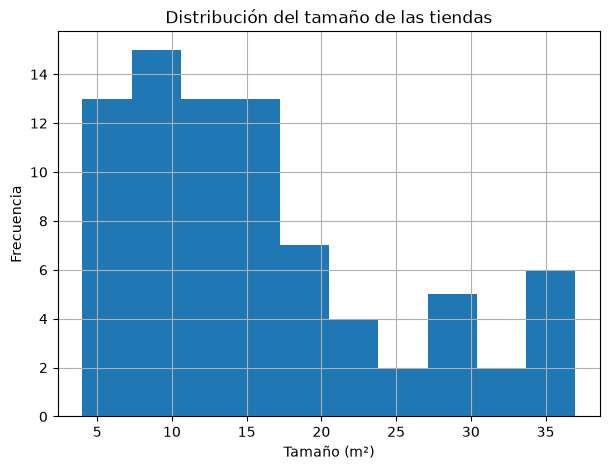

In [26]:
# Histograma del tamaño de las tiendas (en metros cuadrados)
plt.figure(figsize=(7,5))
stores["num_checkouts"].hist()
plt.xlabel("Tamaño (m²)")
plt.ylabel("Frecuencia")
plt.title("Distribución del tamaño de las tiendas")
plt.show()

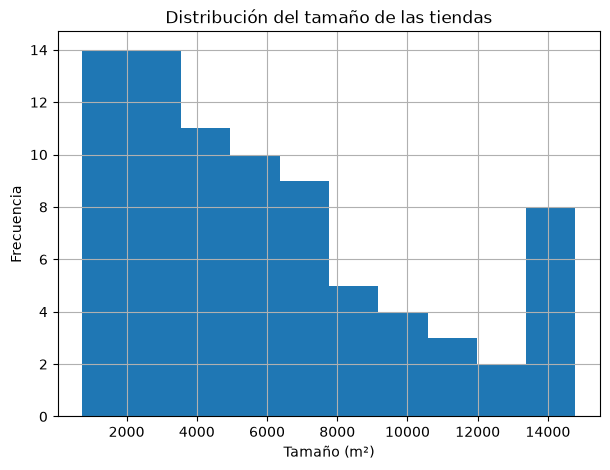

In [27]:
# Histograma del tamaño de las tiendas (en metros cuadrados)
plt.figure(figsize=(7,5))
stores["size_sqm"].hist()
plt.xlabel("Tamaño (m²)")
plt.ylabel("Frecuencia")
plt.title("Distribución del tamaño de las tiendas")
plt.show()

In [28]:
# ver a que formato comercial pertenecen las tiendas
stores["store_format"].value_counts()

store_format
Bodega         35
Express        25
Supercenter    20
Name: count, dtype: int64

In [29]:
# Ver los tamaños promedios y medianos por formato de tienda (para ver la influencia de la distribución)
sqm_median = stores["size_sqm"].groupby(stores["store_format"]).median()
sqm_mean = stores["size_sqm"].groupby(stores["store_format"]).mean()

# Ver el número de cajas promedio y mediano por formato de tienda
checkouts_median = stores["num_checkouts"].groupby(stores["store_format"]).median()
checkouts_mean = stores["num_checkouts"].groupby(stores["store_format"]).mean()

print("Tamaño mediano por formato de tienda:")
print(sqm_median)
print("Tamaño promedio por formato de tienda:")
print(sqm_mean)
print("Número de cajas mediano por formato de tienda:")
print(checkouts_median)
print("Número de cajas promedio por formato de tienda:")
print(checkouts_mean)

Tamaño mediano por formato de tienda:
store_format
Bodega          5442.0
Express         1975.0
Supercenter    11875.0
Name: size_sqm, dtype: float64
Tamaño promedio por formato de tienda:
store_format
Bodega          5549.628571
Express         1937.520000
Supercenter    11830.450000
Name: size_sqm, dtype: float64
Número de cajas mediano por formato de tienda:
store_format
Bodega         14.0
Express         7.0
Supercenter    29.0
Name: num_checkouts, dtype: float64
Número de cajas promedio por formato de tienda:
store_format
Bodega         14.00
Express         6.88
Supercenter    28.85
Name: num_checkouts, dtype: float64


### Transactions

In [30]:
transactions.head(5)

,date,store_id,category,total_transactions,cash_transactions,card_transactions,amount_total,amount_cash,amount_card,units_sold,avg_ticket,has_promotion,replenishment_signal
0,2023-01-01,STR_001,Abarrotes,833,NaN,326,244732.98,NaN,101822.79,2299.0,NaN,0,NaN
1,2023-01-02,STR_001,Abarrotes,1298,750.0,548,373235.09,222834.25,150400.84,3011.0,287.55,0,NaN
2,2023-01-03,STR_001,Abarrotes,1614,931.0,683,404249.92,239802.59,164447.33,3652.0,250.46,0,1546.00
3,2023-01-04,STR_001,Abarrotes,1726,972.0,754,423176.07,246810.92,176365.15,4165.0,245.18,0,1699.25
4,2023-01-05,STR_001,Abarrotes,2159,1028.0,675,458064.93,266559.26,191505.67,3553.0,268.98,1,1871.00


In [31]:
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 203958 entries, 0 to 203957
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   date                  203958 non-null  str    
 1   store_id              203958 non-null  str    
 2   category              203958 non-null  str    
 3   total_transactions    203958 non-null  int64  
 4   cash_transactions     191835 non-null  float64
 5   card_transactions     203958 non-null  int64  
 6   amount_total          203958 non-null  float64
 7   amount_cash           191835 non-null  float64
 8   amount_card           203958 non-null  float64
 9   units_sold            197840 non-null  float64
 10  avg_ticket            199084 non-null  float64
 11  has_promotion         203958 non-null  int64  
 12  replenishment_signal  202998 non-null  float64
dtypes: float64(7), int64(3), str(3)
memory usage: 20.2 MB


In [32]:
transactions.describe()

,total_transactions,cash_transactions,card_transactions,amount_total,amount_cash,amount_card,units_sold,avg_ticket,has_promotion,replenishment_signal
count,203958.000000,191835.000000,203958.000000,2.039580e+05,1.918350e+05,2.039580e+05,197840.000000,199084.000000,203958.000000,202998.000000
mean,613.513473,273.983720,313.100678,1.705813e+05,7.162369e+04,9.890820e+04,1175.413491,411.763939,0.199772,614.452543
std,631.768046,323.685182,286.558478,1.504457e+05,7.168713e+04,8.807257e+04,1264.963992,303.644892,0.399830,538.099510
min,14.000000,3.000000,11.000000,6.922320e+03,2.721280e+03,4.201040e+03,22.000000,69.860000,0.000000,34.670000
25%,228.000000,77.000000,136.000000,7.879817e+04,3.051927e+04,4.489869e+04,418.000000,182.440000,0.000000,249.860000
50%,424.000000,169.000000,234.000000,1.299652e+05,5.146228e+04,7.487742e+04,793.000000,297.030000,0.000000,447.570000
75%,783.000000,352.000000,399.000000,2.133239e+05,8.681946e+04,1.244189e+05,1487.000000,534.140000,0.000000,809.570000
max,15194.000000,8387.000000,6827.000000,4.050996e+06,2.294517e+06,2.269315e+06,31936.000000,1931.740000,1.000000,7064.000000


In [33]:
# Convertir las fechas
transactions["date"] = pd.to_datetime(transactions["date"],format="%Y-%m-%d")
print(f"fecha de inicio: {transactions['date'].min()}")
print(f"fecha de fin: {transactions['date'].max()}")

fecha de inicio: 2023-01-01 00:00:00
fecha de fin: 2024-02-29 00:00:00


In [34]:
# Explorar las ventas de un día para una tienda específica (entender realmente que información trae el dataframe)
store_id = "STR_003"
date = pd.to_datetime("2023-01-01")
transactions_filtered = transactions[(transactions["store_id"] == store_id) & (transactions["date"] == date)]
transactions_filtered.groupby("category")["amount_total"].sum()

category
Abarrotes           195335.26
Bebidas              81863.15
Cuidado_Personal     88618.89
Electronica         118275.18
Hogar               107167.81
Ropa                 89576.10
Name: amount_total, dtype: float64

In [35]:
transactions_filtered.groupby("category")["units_sold"].sum()

category
Abarrotes           2888.0
Bebidas              940.0
Cuidado_Personal    1086.0
Electronica          490.0
Hogar                377.0
Ropa                 436.0
Name: units_sold, dtype: float64

In [36]:
# Explorar ausentes o nulos en units_sold
df_isna_units_sold = transactions[transactions["units_sold"].isna()]
df_isna_units_sold.head(2)

,date,store_id,category,total_transactions,cash_transactions,card_transactions,amount_total,amount_cash,amount_card,units_sold,avg_ticket,has_promotion,replenishment_signal
39,2023-02-09,STR_001,Abarrotes,1363,661.0,702,289212.96,140530.81,148682.15,NaN,212.19,0,1839.57
81,2023-03-23,STR_001,Abarrotes,1889,859.0,638,366274.09,204891.12,161382.97,NaN,244.67,1,2000.00


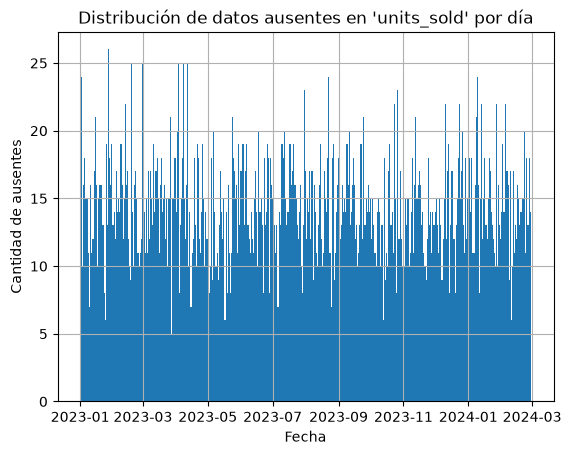

In [37]:
# ver la distribución de los datos ausentes por día
df_isna_units_sold["date"].hist(bins=len(df_isna_units_sold["date"].unique()))
plt.title("Distribución de datos ausentes en 'units_sold' por día")
plt.xlabel("Fecha")
plt.ylabel("Cantidad de ausentes")
plt.show()

In [38]:
# En data_dictionary.md se dice El dataset contiene datos faltantes en algunas columnas como resultado 
# de fallas en sistemas de punto de venta y problemas de conectividad. Algunas tiendas tienen periodos 
# completos sin datos.

# Se me ocurre que tal vez las columnas tengan relación; voy a revisar replenishment_signal

# Explorar los datos faltantes en la columna "replenishment_signal" a lo largo del tiempo.
transactions.loc[transactions["replenishment_signal"].isna(),"date"].value_counts().sort_index()

date
2023-01-01    480
2023-01-02    480
Name: count, dtype: int64

In [39]:
# Esto permite ver que las fechas de ausentes no coinciden entre replenishment_signal y units_sold

## Preguntas básicas de interés para el negocio

En esta sección se desarrollaran las preguntas básicas de estadística descritiva y que sentarán las bases para hacer estadística inferencial y eventualmente responder las preguntas significas o importantes para el negocio

### 1. ¿Cómo se distribuye la actividad comercial del negocio entre las tiendas y categorías, y qué diferencias relevantes existen en sus niveles de ventas y volumen de transacciones?

In [40]:
# Evaluar la distribución de ventas por tienda.
# Incluyendo 3 puntos de interés: medias y medianas, desviación estándar y asimetría.
sales_distribution = (
    transactions
    .groupby("store_id")["amount_total"]
    .agg(
        registros="count",
        media="mean",
        mediana="median",
        desviacion_std="std",
        asimetria="skew",
        minimo="min",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        maximo="max"
    )
)

# Agrego a este dataframe el coeficiente de variación (cv) 
sales_distribution["cv"] = (
    sales_distribution["desviacion_std"]
    / sales_distribution["media"]
)
# Agrego a este dataframe el rango intercuartílico (iqr)
sales_distribution["iqr"] = (
    sales_distribution["q3"] - sales_distribution["q1"]
)
# Redondeo todos los valores a 2 decimales para mejor visualización.
sales_distribution = sales_distribution.round(2)

In [41]:
# Ordernar por mayores ventas promedio
sales_distribution.sort_values("media", ascending=False).head(10)

,registros,media,mediana,desviacion_std,asimetria,minimo,q1,q3,maximo,cv,iqr
store_id,,,,,,,,,,,
STR_017,2550,457372.33,390611.54,296159.19,4.52,73371.37,293127.67,539307.18,4050995.63,0.65,246179.51
STR_001,2550,411215.90,349059.02,263148.49,3.97,68968.24,253202.94,491510.34,3951996.05,0.64,238307.40
STR_011,2550,368658.85,316707.76,228103.83,3.53,66157.26,236524.92,434501.90,2493550.15,0.62,197976.98
STR_014,2550,354189.33,302653.50,223723.86,4.03,48859.81,223179.38,419820.16,3126195.12,0.63,196640.78
STR_007,2550,333757.45,284801.74,209393.84,3.80,58701.21,208091.95,403663.52,3217912.66,0.63,195571.57
STR_008,2550,333198.11,288519.48,210135.58,3.91,57919.55,205934.53,398701.38,2759254.21,0.63,192766.85
STR_015,2550,318206.09,271892.53,208650.35,4.64,54927.26,201160.16,373346.46,3650256.43,0.66,172186.29
STR_031,2550,294775.65,252859.91,186243.97,3.86,45301.84,185963.35,351040.18,2620107.03,0.63,165076.82
STR_004,2550,291741.98,251856.82,185187.39,3.94,41231.17,185715.84,343384.20,2351461.52,0.63,157668.36


Observaciones: 
- Los valores máximos son hasta de 1 orden de magnitud mayor que la media.
- La desviación standar es bastante elevada es casi la mitad del valor de la media (hay demasiada dispersión en los datos; aun se desconoce el origen: promociones, festivos)

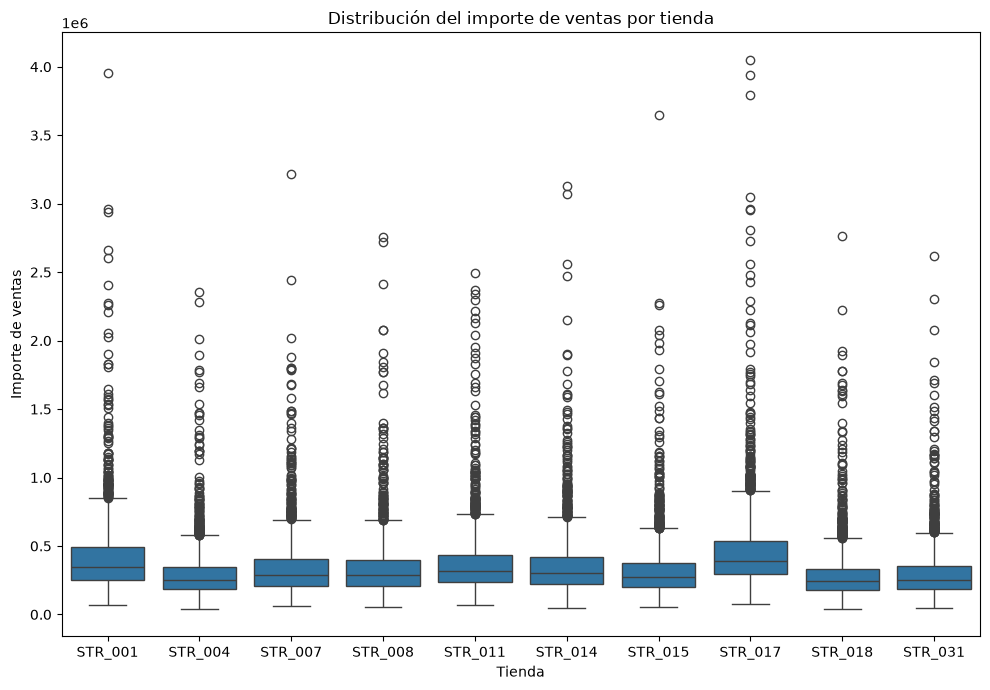

In [42]:
# Seleccionar las 10 tiendas con mayores ventas
top_stores = sales_distribution.sort_values("media", ascending=False).head(10).index
plt.figure(figsize=(10, 7))
sns.boxplot(
    data=transactions[transactions["store_id"].isin(top_stores)],
    x="store_id",
    y="amount_total"
)

plt.title("Distribución del importe de ventas por tienda")
plt.xlabel("Tienda")
plt.ylabel("Importe de ventas")
plt.tight_layout()
plt.show()

Observaciones:

- La tienda STR_017 tiene ventas ligeramente mayores a las demás tiendas.
- Presencia de outliers y la heterogeneidad de las ventas sugiere que hay factores que genera incrementos en las ventas de las tiendas. Esto da pie a explorar si las diferencias de ventas se deben a los tamaños de tienda; y si los outliers se deben a los eventos (festivos o promociones).


In [43]:
# Ahora evaluar por la asimetría
sales_distribution.sort_values("asimetria", ascending=False).head(10)

,registros,media,mediana,desviacion_std,asimetria,minimo,q1,q3,maximo,cv,iqr
store_id,,,,,,,,,,,
STR_019,2550,199179.56,169545.60,134004.06,4.96,37152.23,125088.88,235819.72,2213129.74,0.67,110730.83
STR_048,2550,128842.72,110270.02,82607.97,4.75,17210.23,82399.98,153424.20,1358726.13,0.64,71024.21
STR_015,2550,318206.09,271892.53,208650.35,4.64,54927.26,201160.16,373346.46,3650256.43,0.66,172186.29
STR_017,2550,457372.33,390611.54,296159.19,4.52,73371.37,293127.67,539307.18,4050995.63,0.65,246179.51
STR_005,2550,215244.16,183275.06,141242.81,4.42,29005.27,135779.39,254893.06,2285529.85,0.66,119113.67
STR_025,2550,224827.95,193236.24,145002.49,4.34,26572.74,142944.17,267588.20,2182333.35,0.64,124644.03
STR_018,2550,285328.39,242195.99,189712.83,4.24,39662.35,179360.35,332383.54,2763079.11,0.66,153023.19
STR_051,2550,219565.35,189109.67,137404.62,4.16,26766.27,139964.66,260836.91,2047221.02,0.63,120872.25
STR_003,2550,282844.44,243844.51,178803.80,4.14,46500.26,179830.10,340178.41,2637174.61,0.63,160348.32


Observaciones:
- Asimetría positiva (indica cola hacia la derecha) con media mayor a la mediana (consistente la cola hacia la derecha)
- La tienda 19 tiene la mayor asimetría con 4.96
- La tienda 17 (la mayor en ventas promedio) tiene una asimetría menor que la tienda 19, lo que indica que sus ventas están más concentradas alrededor de la media.
- Estos resultados justifican la investigación de los valores elevados y si estos corresponden a promociones o festivos o si es propio de la dinámica de ventas.

### Fase 1. Cuantificar los picos de ventas

In [44]:
percentiles = round(transactions["amount_total"].quantile([0.25, 0.50, 0.90, 0.95, 0.99]), 2)
percentiles

0.25     78798.17
0.50    129965.23
0.90    329045.89
0.95    424963.03
0.99    722050.27
Name: amount_total, dtype: float64

In [45]:
round(percentiles[0.99]/percentiles[0.50],2)

np.float64(5.56)

Observaciones:

- 50% de las ventas tienen un importe menor o igual a 129965.23
- Existe una diferencia considerable entre los valores centrales y las colas (p99/p50 = 5.56)

Limitaciones: 
- Cada observación representa una fecha, tienda y categoría (no se comparan las ventas totales de cada tienda por día).
- No todas las tiendas y categorías tienen el mismo nivel de ventas; además


In [46]:
#Calcular percentiles de ventas por tienda y por categoría
percentiles_by_store_category = transactions.groupby(["store_id", "category"])["amount_total"].quantile([0.25, 0.50, 0.90, 0.95, 0.99]).unstack()
percentiles_by_store_category = round(percentiles_by_store_category, 2)
percentiles_by_store_category.sort_values(by=0.50, ascending=False).head(10)

,,0.25,0.50,0.90,0.95,0.99
store_id,category,,,,,
STR_017,Abarrotes,480080.97,606512.50,998329.46,1198439.50,2705185.14
STR_001,Abarrotes,427708.26,560102.41,940623.25,1123706.86,2122893.55
STR_011,Abarrotes,389527.20,485035.18,828209.86,1002253.28,1702861.53
STR_014,Abarrotes,375228.86,470375.95,781313.97,931246.46,1764770.83
STR_007,Abarrotes,347529.49,444184.25,726512.36,851402.69,1690737.55
STR_008,Abarrotes,350896.57,443962.03,754086.69,973394.68,1770921.87
STR_017,Electronica,352887.13,432433.92,716612.77,881141.23,1543414.66
STR_015,Abarrotes,324112.11,414794.22,725972.71,861126.35,1709067.52
STR_017,Hogar,324369.27,410041.71,694006.60,795167.00,1369252.03


In [47]:
percentiles_by_store_category["p99_p95"] = percentiles_by_store_category[0.99]/percentiles_by_store_category[0.95]
percentiles_by_store_category["p99_p90"] = percentiles_by_store_category[0.99]/percentiles_by_store_category[0.90]
tmp = percentiles_by_store_category.reset_index()

In [48]:
tmp[tmp["store_id"].isin(["STR_017"])]

,store_id,category,0.25,0.5,0.9,0.95,0.99,p99_p95,p99_p90
96,STR_017,Abarrotes,480080.97,606512.50,998329.46,1198439.50,2705185.14,2.257256,2.709712
97,STR_017,Bebidas,249995.83,315316.31,503320.20,594468.73,986717.86,1.659831,1.960418
98,STR_017,Cuidado_Personal,202831.60,251945.92,413628.99,478219.80,945478.15,1.977079,2.285812
99,STR_017,Electronica,352887.13,432433.92,716612.77,881141.23,1543414.66,1.751609,2.153764
100,STR_017,Hogar,324369.27,410041.71,694006.60,795167.00,1369252.03,1.721968,1.972967
101,STR_017,Ropa,323030.61,392104.14,662608.74,818908.49,1626402.75,1.986062,2.454545


Observaciones:

- El p99 dobla al p95 y casi triplica al p90 y además estos valores cambian considerablemente entre diferentes categorías y tiendas.
- Esto indica que hay una gran variabilidad en los valores extremos de las ventas según la categoría y la tienda por lo que se contarán los picos considerando cada tienda y cada categoría por separado.

In [49]:
# Contar picos
p95_by_group = (
    transactions.groupby(["store_id", "category"])["amount_total"]
    .transform("quantile", q=0.95)
)

transactions["peak_p95"] = transactions["amount_total"] > p95_by_group
transactions["peak_p95"].value_counts()

peak_p95
False    193398
True      10560
Name: count, dtype: int64

In [50]:
# Verlo en porcentajes
total = transactions["peak_p95"].count()
percentages = round(transactions["peak_p95"].value_counts() / total * 100, 2)
percentages

peak_p95
False    94.82
True      5.18
Name: count, dtype: float64

Observación:

- Se detectaron ~10k (~5%) picos por encima del percentil 95 

In [53]:
peak_summary = (
    transactions.groupby(["store_id", "category"])["peak_p95"]
    .agg(
        total_observations="size",
        peak_count="sum",
        peak_rate="mean"
    )
    .sort_values("peak_rate", ascending=False)
)

peak_summary.head(10)

total_observations  peak_count  peak_rate
store_id category                                                   
STR_055  Abarrotes                        422          22   0.052133
         Bebidas                          422          22   0.052133
         Cuidado_Personal                 422          22   0.052133
         Electronica                      422          22   0.052133
         Hogar                            422          22   0.052133
         Ropa                             422          22   0.052133
STR_064  Ropa                             423          22   0.052009
         Hogar                            423          22   0.052009
         Electronica                      423          22   0.052009
STR_045  Ropa                             423          22   0.052009

In [54]:
peak_summary.sample(20)

,,total_observations,peak_count,peak_rate
store_id,category,,,
STR_008,Hogar,425,22,0.051765
STR_067,Hogar,425,22,0.051765
STR_013,Cuidado_Personal,425,22,0.051765
STR_032,Hogar,425,22,0.051765
STR_016,Electronica,425,22,0.051765
STR_074,Ropa,425,22,0.051765
STR_073,Abarrotes,425,22,0.051765
STR_045,Hogar,423,22,0.052009
STR_003,Cuidado_Personal,425,22,0.051765


In [55]:
peak_magnitude = percentiles_by_store_category.copy()

peak_magnitude["P99_P50_ratio"] = (
    peak_magnitude[0.99] / peak_magnitude[0.50]
)

peak_magnitude.sort_values(
    "P99_P50_ratio",
    ascending=False
).head(10)

,,0.25,0.5,0.9,0.95,0.99,p99_p95,p99_p90,P99_P50_ratio
store_id,category,,,,,,,,
STR_010,Cuidado_Personal,96536.81,119549.22,204855.19,258066.15,618173.54,2.395407,3.017612,5.170871
STR_019,Abarrotes,206608.96,258238.96,443962.87,516725.89,1227465.20,2.375467,2.764792,4.753215
STR_025,Abarrotes,229087.63,302189.28,533117.14,639798.49,1425647.17,2.228275,2.674172,4.717729
STR_009,Hogar,142041.34,182897.51,301580.45,379738.30,861857.64,2.269609,2.857803,4.712244
STR_010,Ropa,145138.60,185073.77,311575.07,367704.72,865756.86,2.354489,2.778646,4.677901
STR_018,Bebidas,154467.29,194470.32,318138.58,361275.10,909124.54,2.516433,2.857637,4.674876
STR_007,Hogar,229597.64,288745.67,501687.27,605776.09,1347147.89,2.223838,2.685234,4.665517
STR_028,Bebidas,102968.22,128508.17,208586.19,255103.59,597988.44,2.344100,2.866865,4.653311
STR_043,Hogar,103890.46,128679.76,214011.46,259009.55,590067.81,2.278170,2.757179,4.585553


In [56]:
# Seleccionar observaciones de picos por encima del percentil 95
# Busco ver las ventas concretas que superen el percentil 95
peak_observations = (
    transactions.loc[transactions["peak_p95"]]
    .sort_values("amount_total", ascending=False)
)

peak_observations[
    [
        "date",
        "store_id",
        "category",
        "amount_total",
        "has_promotion"
    ]
].head(20)

,date,store_id,category,amount_total,has_promotion
41122,2023-11-19,STR_017,Abarrotes,4050995.63,0
364,2023-12-31,STR_001,Abarrotes,3951996.05,1
41121,2023-11-18,STR_017,Abarrotes,3937150.79,0
41157,2023-12-24,STR_017,Abarrotes,3796051.26,0
36057,2023-12-24,STR_015,Abarrotes,3650256.43,0
15657,2023-12-24,STR_007,Abarrotes,3217912.66,0
33507,2023-12-24,STR_014,Abarrotes,3126195.12,0
33471,2023-11-18,STR_014,Abarrotes,3068359.71,0
42439,2023-12-31,STR_017,Electronica,3051948.94,1
357,2023-12-24,STR_001,Abarrotes,2963663.70,0


#### Conclusión Fase 1

- Se detectaron aproximadamente 10k (~5%) picos por encima del percentil 95.
- Al analizar la magnitud de los picos, algunos valores extremos se destacan significativamente en comparación con la mediana (P99/P50 ratio alto).
- La exploración inicial muestra que las fechas con mayores picos de ventas ocurren el 18 y 19 de noviembre, el 24 y el 31 de diciembre.
- La categoría principal de los picos es abarrotes, seguida de electrónica.
- Esto sugiere que los picos podrían estar relacionados con eventos estacionales o festivos, como la Navidad y el fin de año; por lo tanto, es crucial analizar las fechas específicas de los picos.
- Es importante investigar las fechas de estos picos para determinar si coinciden con promociones, festivos, Buen Fin, temporadas especiales u otros patrones temporales.

Limitaciones: 
- Se debería considerar la posibilidad de que algunos picos pueden ser anomalías no relacionadas con eventos externos.

### Fase 2. Investigar cuándo y dónde ocurren los picos

Dados los resultados de la fase 1 (Cuantificar picos de ventas), se plantea la siguiente hipótesis:

```
H1: Los picos de ventas se concentran en noviembre y diciembre
```


In [57]:
# Revisar la frecuencia de los picos de ingresos según el mes
# Agrupar las observaciones por mes
monthly_peaks = (
    transactions.groupby(transactions["date"].dt.month)
    ["peak_p95"]
    .agg(
        total_observations="count",
        peak_count="sum",
        peak_rate="mean"
    )
)

monthly_peaks["peak_rate"] = (
    monthly_peaks["peak_rate"] * 100
).round(2)

monthly_peaks.index.name = "month"
monthly_peaks.sort_values("peak_rate", ascending=False)


,total_observations,peak_count,peak_rate
month,,,
12,14880,5394,36.25
11,14400,2913,20.23
9,14400,564,3.92
7,14880,509,3.42
8,14880,303,2.04
4,14400,268,1.86
10,14880,236,1.59
6,14400,213,1.48
5,14880,57,0.38


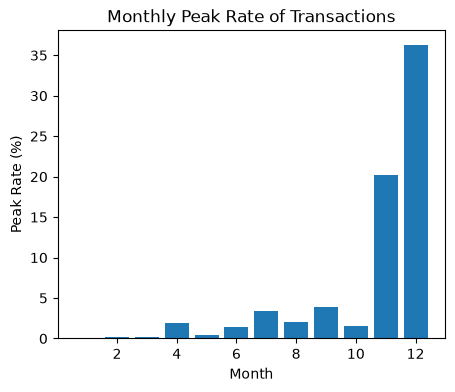

In [58]:
fig, ax = plt.subplots(figsize=(5, 4))
x = monthly_peaks.index
y = monthly_peaks["peak_rate"]
ax.bar(x, y)
ax.set_xlabel("Month")
ax.set_ylabel("Peak Rate (%)")
ax.set_title("Monthly Peak Rate of Transactions")
plt.show()

Observación:

- Se observa un patrón muy marcado en los picos de ventas según el mes, con incrementos significativos en noviembre y diciembre, lo que sugiere un comportamiento estacional relacionado con festividades y eventos especiales.
- Esto coincide con las observaciones anteriores sobre las fechas específicas de los picos, como el 18 y 19 de noviembre y el 24 y 31 de diciembre.



In [59]:
# Explorar fechas concretas con picos y cuantificarlas
peak_dates = (
    transactions.loc[transactions["peak_p95"]]
    .assign(
        date=lambda df: pd.to_datetime(df["date"])
    )
    .groupby("date")
    .size()
    .sort_values(ascending=False)
)

peak_dates.head(15)

date
2023-12-24    480
2023-11-19    480
2023-11-18    480
2023-12-31    480
2023-11-17    479
2023-12-25    452
2023-12-15    420
2023-12-16    386
2023-12-30    380
2023-12-02    373
2023-12-23    366
2023-11-20    363
2023-12-09    362
2023-12-17    307
2023-09-30    274
dtype: int64

Observación:

- Encontrar un conteo de 480 significa que todas las categorías (6) en todas las tiendas (80) tuvieron un pico (6 x 80 = 480)
- Esto respalda la hipótesis propuesta al inicio de esta sección
- Para comprobar estadísticamente que los picos se concentran en noviembre y diciembre aplicaré una Xi2 (chi cuadrada)

Hipótesis:

- H0: la proporción de picos es independiente de si la observación pertenece a noviembre-diciembre o al resto del año.
- H1: la proporción de picos difiere entre ambos periodos

In [61]:
# Hacer las transformaciones categóricas para poder relacionarlo con Xi2

transactions["peak_p95"] = transactions["peak_p95"].astype(bool)
transactions["period"] = transactions["date"].dt.month.isin([11, 12]).map({
    True: "Nov-Dic",
    False: "Resto del año"
})

contingency_table = pd.crosstab(
    transactions["period"],
    transactions["peak_p95"]
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

peak_rates = (
    transactions.groupby("period")["peak_p95"]
    .mean()
    .mul(100)
    .round(2)
)

In [62]:
print("Tabla de contingencia:")
print(contingency_table)

print("Tasa de picos (%):")
print(peak_rates)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"Grados de libertad: {dof}")
print(f"Valor p: {p_value:.3e}")


Tabla de contingencia:
peak_p95        False  True 
period                      
Nov-Dic         20973   8307
Resto del año  172425   2253
Tasa de picos (%):
period
Nov-Dic          28.37
Resto del año     1.29
Name: peak_p95, dtype: float64
Chi-cuadrado: 37454.39
Grados de libertad: 1
Valor p: 0.000e+00


#### Conclusión Fase 2

- Las observaciones de noviembre y diciembre presentaron una tasa de picos de ventas del ~28% en contraste al 1% correspondiente al resto del año.
- La prueba Xi2 detectó una asociación estadísticamente significativa entre el periodo y la ocurrencia de picos con un Xi2 = 37454.39; grados de libertad (dof) = 1 y p-value < 0.001
- Se rechaza la hipótesis nula "la proporción de picos es independiente de si la observación pertenece a noviembre-diciembre o al resto del año."; es decir, que la evidencia suguiere la proporción de los picos es mayor durante noviembre-diciembre que en el resto del año.


Limitación:

- La prueba supone independencia entre las observaciones, esto pudiera ser falso dado que los periodos festivos como navidad pueden tener una especie de efecto acumulativo.





## Otras áreas de interés para desarrollos futuros
- Determinar las ventas por región
- Determinar tendencias
- Categorizar por tipo de cliente

NOTA: Esto podría ser interesante; con un poco más de tiempo se pueden explorar muchas más posibilidades